In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [15]:
df = pd.read_csv('HR-Employee-Attrition.csv')

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [16]:
# Display first 5 rows
print(df.head())

# Display last 5 rows
print(df.tail())

# Dataset information
print(df.info())

# Statistical information
print(df.describe())

# Check missing values
print(df.isnull().sum())

   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOptionLevel  \
0  ...

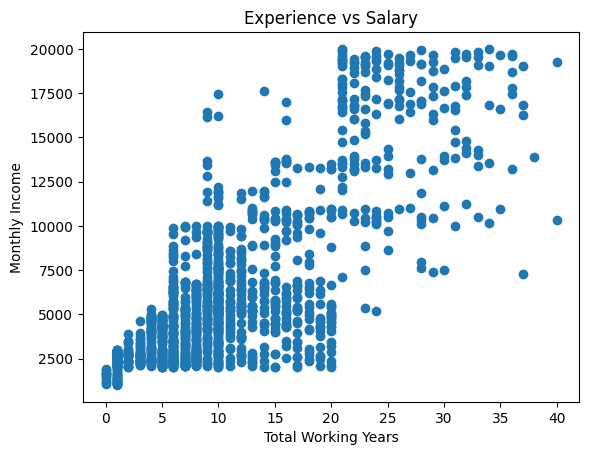

In [17]:
plt.scatter(df['TotalWorkingYears'], df['MonthlyIncome'])

plt.xlabel('Total Working Years')
plt.ylabel('Monthly Income')

plt.title('Experience vs Salary')

plt.show()

In [13]:
X = df[['TotalWorkingYears']]

y = df['MonthlyIncome']

print(X.head())
print(y.head())

   TotalWorkingYears
0                  8
1                 10
2                  7
3                  8
4                  6
0    5993
1    5130
2    2090
3    2909
4    3468
Name: MonthlyIncome, dtype: int64


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 1176
Testing data: 294


In [19]:
model = LinearRegression()

In [20]:
model.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


In [21]:
print("Coefficient:", model.coef_)

print("Intercept:", model.intercept_)

Coefficient: [465.18736646]
Intercept: 1210.0833301260527


In [22]:
y_pred = model.predict(X_test)

print("Actual Salary:")
print(y_test.values)

print("Predicted Salary:")
print(y_pred)

Actual Salary:
[ 8463  4450  1555  9724  5914  2579  4230  2232  8865  2269  3294 10231
  5933  2213  3375  4968  6294  2743 11849 17007  3479  5070  9204  5605
  6392 19586  2318  4037  3420  5957  5294  5472  4244  7491  6134  7823
 13757  2107  3441  3591  8686  5473  4087  2821  2851  5249  9094  5324
  6796  1859 17861  4821 19537  6125  2974  4998  2741  5968  6142  5042
  9756  1416  7446 17639  4777  5916  6214  4284  3310 16437  5507 18947
  9602  4312  6623 14756  4724  6500 10252 11916 18606  6389 17875  2096
  7336  3162  7082  5985  5175  4011  5993  1232 13341  2476  7428  7143
  8620  4449  4591  9071 19045  7655  7654  2534 10999  8740  5258  4648
 13664 19202  5440  5769  6932  9957  1702  3452  5473  9980 15379  3838
  2066  8500  2838 12965  5980  2564  4950 12169  4553  6929  3812  1514
 10266  4508  4420  5429  3230  9824  2696 13973  2154  7406  4374  8726
 13966  2718  4869  2625  2956  5744  5484 10096  4257  3730  6120  4031
  8346  2523 19627  2370  4855  5337

In [23]:
comparison = pd.DataFrame({
    'Actual Salary': y_test.values,
    'Predicted Salary': y_pred
})

print(comparison)

     Actual Salary  Predicted Salary
0             8463       4001.207529
1             4450       3536.020162
2             1555       1675.270697
3             9724      12839.767492
4             5914       8653.081193
..             ...               ...
289           6274       4001.207529
290           5121       4466.394895
291          16880      12839.767492
292           4680       3070.832796
293           4537       4931.582262

[294 rows x 2 columns]


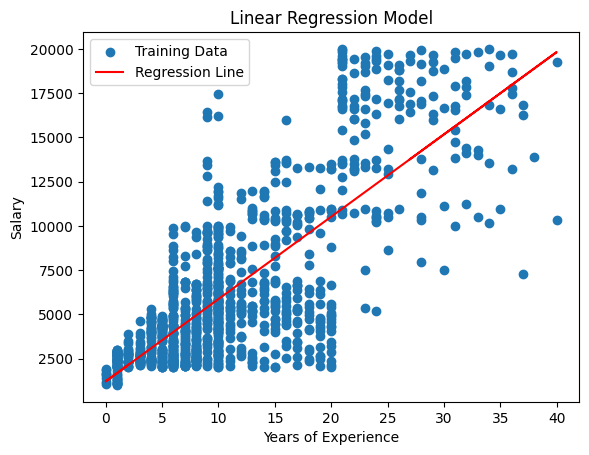

In [24]:
plt.scatter(X_train, y_train, label='Training Data')

plt.plot(
    X_train,
    model.predict(X_train),
    color='red',
    label='Regression Line'
)

plt.xlabel('Years of Experience')
plt.ylabel('Salary')

plt.title('Linear Regression Model')

plt.legend()
plt.show()

In [25]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)

print("MSE:", mse)

print("RMSE:", rmse)

print("R2 Score:", r2)

MAE: 2233.825203946931
MSE: 8820341.547201121
RMSE: 2969.9059828892096
R2 Score: 0.5964229412874165


In [26]:
experience = [[5]]

predicted_salary = model.predict(experience)

print("Experience:", experience[0][0])

print("Predicted Salary:", predicted_salary[0])

Experience: 5
Predicted Salary: 3536.0201624034166


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [27]:
import pickle

with open('linear_regression_model.pkl', 'wb') as file:
    pickle.dump(model, file)

print("Model saved successfully")

Model saved successfully


In [28]:
with open('linear_regression_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

result = loaded_model.predict([[7]])

print("Predicted Salary:", result[0])

Predicted Salary: 4466.394895314363


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [29]:
if 'MonthlyIncome' in df.columns and 'Attrition' in df.columns:
    print("IBM HR Employee Attrition Dataset detected!")
else:
    print("Different dataset or different column names.")

IBM HR Employee Attrition Dataset detected!
